<a href="https://colab.research.google.com/github/ash7064/Breast-Cancer-ML-Detector/blob/main/3ModelsColabWithGraphs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install ucimlrepo


In [ ]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
breast_cancer_wisconsin_diagnostic = fetch_ucirepo(id=17)

# data (as pandas dataframes)
x = breast_cancer_wisconsin_diagnostic.data.features
y = breast_cancer_wisconsin_diagnostic.data.targets

# metadata
print(breast_cancer_wisconsin_diagnostic.metadata)

# variable information
print(breast_cancer_wisconsin_diagnostic.variables)


{'uci_id': 17, 'name': 'Breast Cancer Wisconsin (Diagnostic)', 'repository_url': 'https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic', 'data_url': 'https://archive.ics.uci.edu/static/public/17/data.csv', 'abstract': 'Diagnostic Wisconsin Breast Cancer Database.', 'area': 'Health and Medicine', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 569, 'num_features': 30, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['Diagnosis'], 'index_col': ['ID'], 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1993, 'last_updated': 'Fri Nov 03 2023', 'dataset_doi': '10.24432/C5DW2B', 'creators': ['William Wolberg', 'Olvi Mangasarian', 'Nick Street', 'W. Street'], 'intro_paper': {'title': 'Nuclear feature extraction for breast tumor diagnosis', 'authors': 'W. Street, W. Wolberg, O. Mangasarian', 'published_in': 'Electronic imaging', 'year': 1993, 'url': 'https://www.semanticscholar.org/paper/53

In [ ]:
x

,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [ ]:
y

,Diagnosis
0,M
1,M
2,M
3,M
4,M
...,...
564,M
565,M
566,M
567,M


In [ ]:
MCount = 0;
BCount = 0;

print(y)
for i in range(569):
  if y['Diagnosis'][i] == 'M':
    y['Diagnosis'][i] = 1
    MCount = MCount + 1
  else:
    y['Diagnosis'][i] = 0
    BCount = BCount + 1

y = y.copy().astype(int)

print(y)
print("Number of malignant cells: " + str(MCount))
print("Number of benign cells: " + str(BCount))


    Diagnosis
0           M
1           M
2           M
3           M
4           M
..        ...
564         M
565         M
566         M
567         M
568         B

[569 rows x 1 columns]
     Diagnosis
0            1
1            1
2            1
3            1
4            1
..         ...
564          1
565          1
566          1
567          1
568          0

[569 rows x 1 columns]
Number of malignant cells: 212
Number of benign cells: 357


<ipython-input-7-32e8550cabf4>:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  y['Diagnosis'][i] = 1
<ipython-input-7-32e8550cabf4>:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  y['Diagnosis'][i] = 0


In [ ]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.33, random_state=42)

In [ ]:
x_train

,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
172,15.460,11.89,102.50,736.9,0.12570,0.15550,0.20320,0.10970,0.1966,0.07069,...,18.790,17.04,125.00,1102.0,0.15310,0.35830,0.58300,0.18270,0.3216,0.10100
407,12.850,21.37,82.63,514.5,0.07551,0.08316,0.06126,0.01867,0.1580,0.06114,...,14.400,27.01,91.63,645.8,0.09402,0.19360,0.18380,0.05601,0.2488,0.08151
56,19.210,18.57,125.50,1152.0,0.10530,0.12670,0.13230,0.08994,0.1917,0.05961,...,26.140,28.14,170.10,2145.0,0.16240,0.35110,0.38790,0.20910,0.3537,0.08294
497,12.470,17.31,80.45,480.1,0.08928,0.07630,0.03609,0.02369,0.1526,0.06046,...,14.060,24.34,92.82,607.3,0.12760,0.25060,0.20280,0.10530,0.3035,0.07661
301,12.460,19.89,80.43,471.3,0.08451,0.10140,0.06830,0.03099,0.1781,0.06249,...,13.460,23.07,88.13,551.3,0.10500,0.21580,0.19040,0.07625,0.2685,0.07764
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
71,8.888,14.64,58.79,244.0,0.09783,0.15310,0.08606,0.02872,0.1902,0.08980,...,9.733,15.67,62.56,284.4,0.12070,0.24360,0.14340,0.04786,0.2254,0.10840
106,11.640,18.33,75.17,412.5,0.11420,0.10170,0.07070,0.03485,0.1801,0.06520,...,13.140,29.26,85.51,521.7,0.16880,0.26600,0.28730,0.12180,0.2806,0.09097
270,14.290,16.82,90.30,632.6,0.06429,0.02675,0.00725,0.00625,0.1508,0.05376,...,14.910,20.65,94.44,684.6,0.08567,0.05036,0.03866,0.03333,0.2458,0.06120
435,13.980,19.62,91.12,599.5,0.10600,0.11330,0.11260,0.06463,0.1669,0.06544,...,17.040,30.80,113.90,869.3,0.16130,0.35680,0.40690,0.18270,0.3179,0.10550


In [ ]:
y_train

,Diagnosis
172,1
407,0
56,1
497,0
301,0
...,...
71,0
106,0
270,0
435,1


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

#initializing model
lr = LogisticRegression()

#training/fit x_train, y_train
lr.fit(x_train, y_train)

#preditions
y_pred = lr.predict(x_test)

#accuracy of the model
accuracy_score(y_pred, y_test)

/usr/local/lib/python3.10/dist-packages/sklearn/utils/validation.py:1143: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.9574468085106383

In [ ]:
from sklearn.neural_network import MLPClassifier

#initializing model
mlp = MLPClassifier()

#training/fit x_train, y_train
mlp.fit(x_train, y_train)

#preditions
y_pred = mlp.predict(x_test)

#accuracy of the model
accuracy_score(y_pred, y_test)


/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:1098: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:686: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


0.9521276595744681

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

#initializing model -- adjust # of neighbors
KNN = KNeighborsClassifier(n_neighbors= 7)

#training/fit x_train, y_train
KNN.fit(x_train, y_train)

#preditions
y_pred = KNN.predict(x_test)

#accuracy of the model
accuracy_score(y_pred, y_test)

/usr/local/lib/python3.10/dist-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


0.973404255319149

In [ ]:
print(x_test)
print(y_test)

     radius1  texture1  perimeter1   area1  smoothness1  compactness1  \
204    12.47     18.60       81.09   481.9      0.09965       0.10580   
70     18.94     21.31      123.60  1130.0      0.09009       0.10290   
131    15.46     19.48      101.70   748.9      0.10920       0.12230   
431    12.40     17.68       81.47   467.8      0.10540       0.13160   
540    11.54     14.44       74.65   402.9      0.09984       0.11200   
..       ...       ...         ...     ...          ...           ...   
141    16.11     18.05      105.10   813.0      0.09721       0.11370   
498    18.49     17.52      121.30  1068.0      0.10120       0.13170   
7      13.71     20.83       90.20   577.9      0.11890       0.16450   
541    14.47     24.99       95.81   656.4      0.08837       0.12300   
19     13.54     14.36       87.46   566.3      0.09779       0.08129   

     concavity1  concave_points1  symmetry1  fractal_dimension1  ...  radius3  \
204     0.08005          0.03821     0.192

In [ ]:
#testing point for model
import numpy as np

x_p = np.array(x_test)
y_p = np.array(y_pred)
y_p_test = np.array(y_test)

print("predicted value:        actual value:")
for i in range(len(x_p)):
  print(str(y_p[i]) + "                      " + str(y_p_test[i]))



predicted value:        actual value:
0                      [0]
1                      [1]
1                      [1]
0                      [0]
0                      [0]
1                      [1]
1                      [1]
1                      [1]
0                      [0]
0                      [0]
0                      [0]
1                      [1]
0                      [0]
0                      [1]
0                      [0]
1                      [1]
0                      [0]
0                      [0]
0                      [0]
1                      [1]
1                      [1]
0                      [0]
1                      [1]
0                      [0]
0                      [0]
0                      [0]
0                      [0]
0                      [0]
0                      [0]
1                      [1]
0                      [0]
0                      [0]
0                      [0]
1                      [0]
0                      [0]
0                

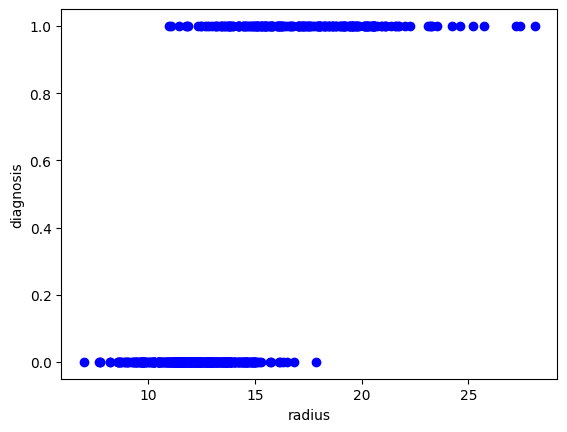

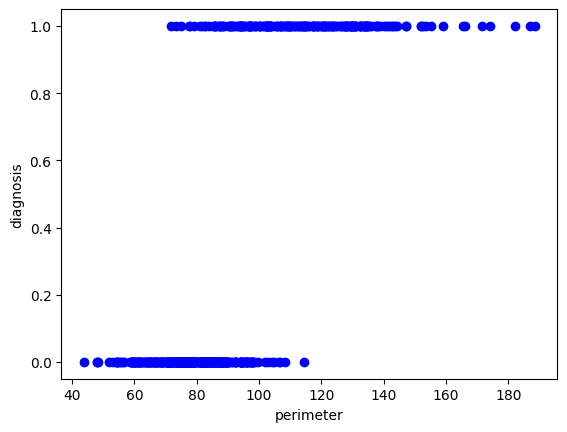

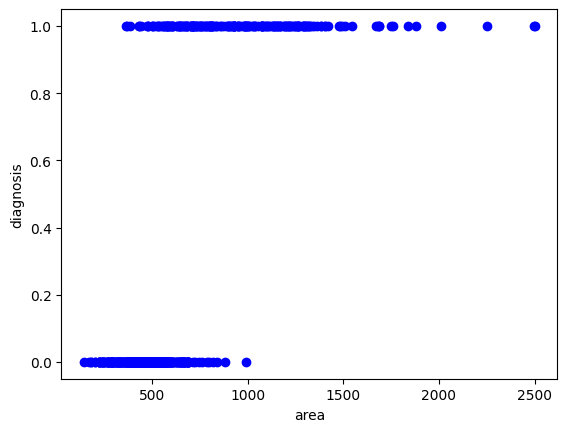

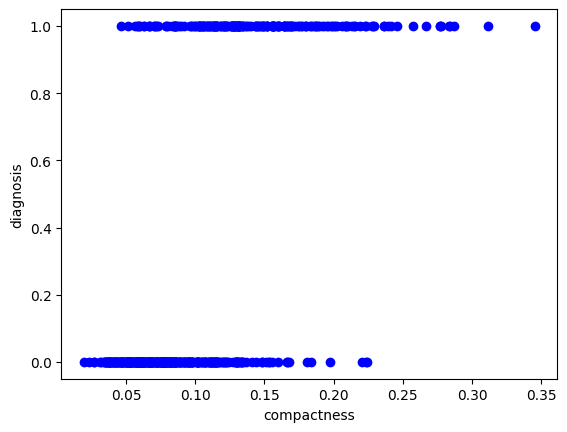

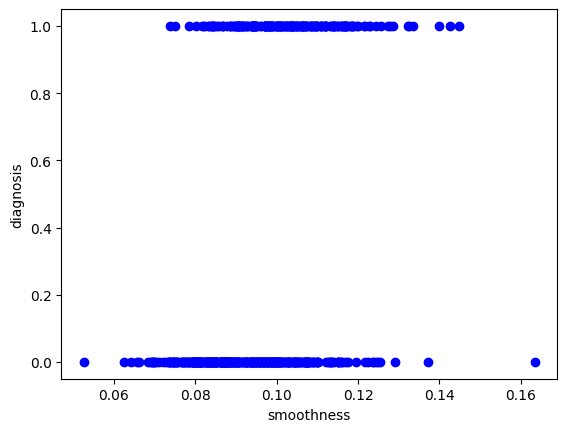

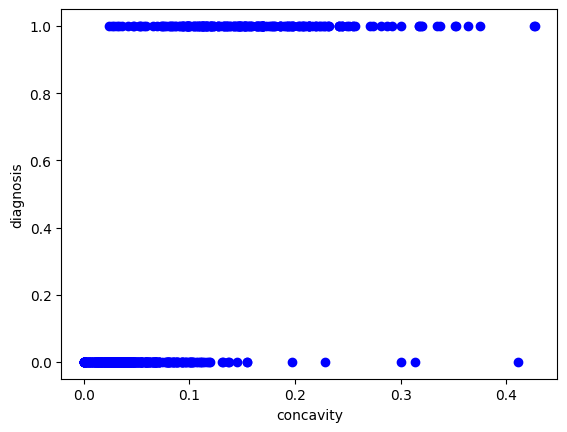

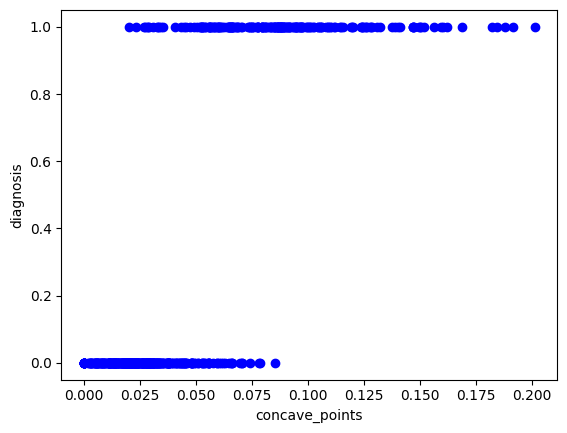

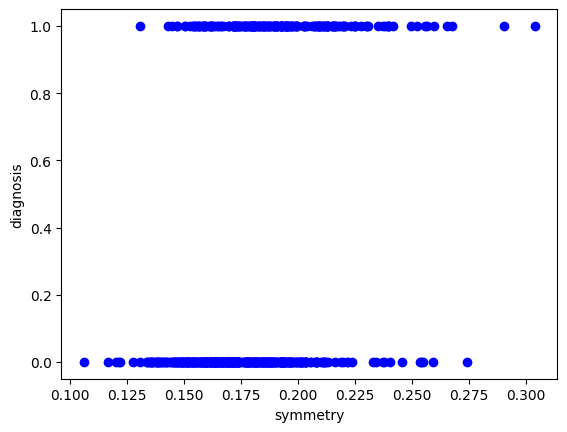

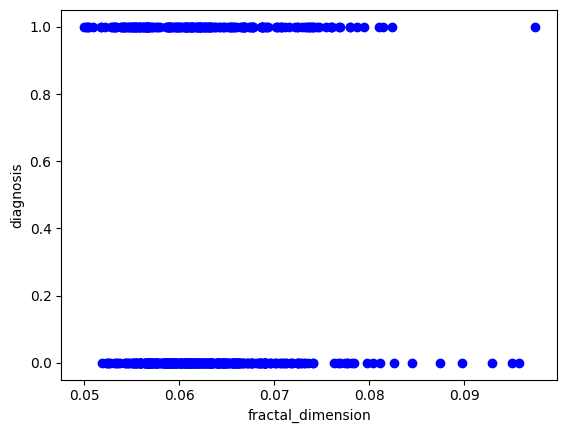

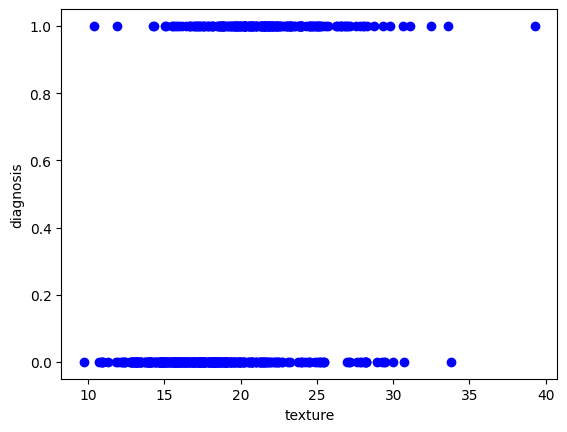

In [ ]:
#Ploting Graphs
import matplotlib.pyplot as plt
import numpy as np

x_plt = np.array(x_train)
y_plt = np.array(y_train)

plt.scatter(x['radius1'], y, c = "blue")
plt.xlabel('radius')
plt.ylabel('diagnosis')
plt.show()

plt.scatter(x['perimeter1'], y, c = "blue")
plt.xlabel('perimeter')
plt.ylabel('diagnosis')
plt.show()

plt.scatter(x['area1'], y, c = "blue")
plt.xlabel('area')
plt.ylabel('diagnosis')
plt.show()

plt.scatter(x['compactness1'], y, c = "blue")
plt.xlabel('compactness')
plt.ylabel('diagnosis')
plt.show()

plt.scatter(x['smoothness1'], y, c = "blue")
plt.xlabel('smoothness')
plt.ylabel('diagnosis')
plt.show()

plt.scatter(x['concavity1'], y, c = "blue")
plt.xlabel('concavity')
plt.ylabel('diagnosis')
plt.show()

plt.scatter(x['concave_points1'], y, c = "blue")
plt.xlabel('concave_points')
plt.ylabel('diagnosis')
plt.show()

plt.scatter(x['symmetry1'], y, c = "blue")
plt.xlabel('symmetry')
plt.ylabel('diagnosis')
plt.show()

plt.scatter(x['fractal_dimension1'], y, c = "blue")
plt.xlabel('fractal_dimension')
plt.ylabel('diagnosis')
plt.show()

plt.scatter(x['texture1'], y, c = "blue")
plt.xlabel('texture')
plt.ylabel('diagnosis')
plt.show()

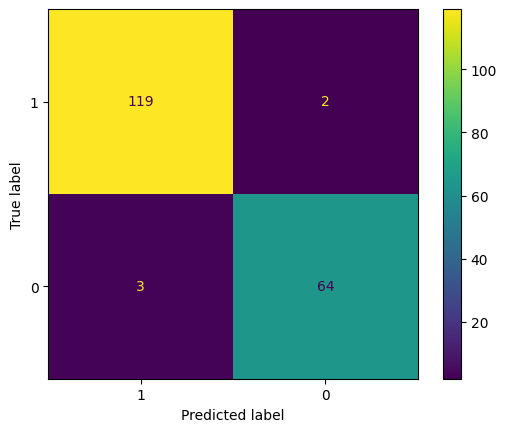

In [ ]:
#Confucian Matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_true = np.array(y_test)
y_pred = np.array(y_pred)
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[1, 0])
disp.plot()
plt.show()

In [ ]:
from joblib import dump, load

import warnings
warnings.filterwarnings("ignore")
!pip -q install streamlit
!pip -q install pyngrok
from pyngrok import ngrok

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.1/8.1 MB 16.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.0/53.0 kB 4.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 195.4/195.4 kB 16.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.8/4.8 MB 35.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 83.0/83.0 kB 6.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.7/62.7 kB 5.0 MB/s eta 0:00:00


In [ ]:
!ngrok authtoken 2beVNYXgJ1r2usnacoAqAbktZ9z_3MCV2gUxGsrTxJKJ39UJ

Authtoken saved to configuration file: /root/.config/ngrok/ngrok.yml


In [ ]:
def launch_website():
  print ("Click this link to try your web app:")
  if (ngrok.get_tunnels() != None):
    ngrok.kill()
  public_url = ngrok.connect()
  print (public_url)
  !streamlit run --server.port 80 app.py >/dev/null


In [ ]:
dump(KNN, "model.joblib")

['model.joblib']

In [ ]:
%%writefile header.py
import streamlit as st

def create_header():
  st.title("Machine Learning Model for Diagnosis of Breast Cancer")
  st.subheader("Please enter the following values for nucleaus features of breast cancer tissue cells below.")


Writing header.py


In [ ]:
%%writefile userinput.py
import streamlit as st

def get_user_input():
  import streamlit as st
  radius = st.number_input("Enter radius")
  texture = st.number_input("Enter texture")
  perimeter = st.number_input("Enter perimeter")
  area = st.number_input("Enter area")
  smoothness = st.number_input("Enter smoothness")
  compactness = st.number_input("Enter compactness")
  concavity = st.number_input("Enter concavity")
  concave_points =st.number_input("Enter concave_points")
  symmetry = st.number_input("Enter symmetry")
  fractal_dimension = st.number_input("Enter fractal_dimension")
  input_features = [['radius', 'texture', 'perimeter', 'area', 'smoothness',
       'compactness', 'concavity', 'concave_points', 'symmetry',
       'fractal_dimension']*3]
  return input_features


Writing userinput.py


In [ ]:
%%writefile predictor.py

def make_prediction(model, input_features):
  return model.predict(input_features)

Writing predictor.py


In [ ]:
%%writefile response.py
import streamlit as st

def get_app_response(prediction):
  if prediction == 1:
    st.write("Malignant")
  else:
    st.write("Benign")

Writing response.py


In [ ]:
%%writefile app.py
import streamlit as st
from joblib import load

#Imports the functions coded above
from header import create_header()
from userinput import get_user_input()
from predictor import make_prediction(model, input_features):
from response import get_app_response(prediction)

#Load our DecisionTree model into web app
model = load("model.joblib")
st.write ("Model uploaded!")

create_header()
input_features = get_user_input()
prediction = make_prediction(model, input_features)
get_app_response(prediction)

Writing app.py


In [ ]:
launch_website()

Click this link to try your web app:
NgrokTunnel: "https://a155-34-135-195-115.ngrok-free.app" -> "http://localhost:80"


In [ ]:
mask = y['Diagnosis'].isin([1])
mal_patients = x[mask]

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Creating dataset
# data_1 = mal_patients['area1']
data_1 = mal_patients['area1']
data_2 = mal_patients['area2']
data_3 = mal_patients['area3']
data = [data_1, data_2, data_3]

fig = plt.figure()
ax = fig.add_subplot(111)

# Creating axes instance
bp = ax.boxplot(data, patch_artist = True,
                notch ='True', vert = 0)
# x-axis labels
ax.set_yticklabels(['data_1', 'data_2', 'data_3'])